# Task 04_Hai – Supervised Learning – Classification Pipeline
# 1. Import thư viện và đọc file cleaned_data.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_data.csv")
print(df.columns)


Index(['product_name', 'price', 'tv_type', 'screen_size', 'resolution',
       'screen_type', 'operating_system', 'ram', 'rom', 'release_year',
       'manufacturer', 'model_name', 'rating', 'num_reviews', 'specifications',
       'source', 'monthly_views', 'monthly_orders', 'customer_rating',
       'stock_quantity', 'data_date'],
      dtype='str')


# 2. Xác định biến mục tiêu và kiểm tra phân bố các class:
Tạo Price_tier từ price với các nhóm:

1.Low(price <25%)

2.Medium(25%< price <75%)

3.High(price >75%)


In [ ]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)

df["Price_Tier"] = pd.cut(df["price"],bins=[-float("inf"), q1, q3, float("inf")],labels=["Low", "Medium", "High"]
)

In [9]:
# Kiểm tra phân bố class:
print(df["Price_Tier"].value_counts())
print(df["Price_Tier"].value_counts(normalize=True) * 100)
print("\n=== NHẬN XÉT CLASS IMBALANCE ===")
print("Class Medium chiếm tỷ lệ cao nhất, trong khi Low và High có tỷ lệ gần nhau.")
print("Dữ liệu có sự chênh lệch giữa các class nhưng không bị mất cân bằng nghiêm trọng.")

Price_Tier
Medium    345
Low       173
High      171
Name: count, dtype: int64
Price_Tier
Medium    50.072569
Low       25.108853
High      24.818578
Name: proportion, dtype: float64

=== NHẬN XÉT CLASS IMBALANCE ===
Class Medium chiếm tỷ lệ cao nhất, trong khi Low và High có tỷ lệ gần nhau.
Dữ liệu có sự chênh lệch giữa các class nhưng không bị mất cân bằng nghiêm trọng.


# 3. Xác định x (biến dự đoán) và y (biến mục tiêu) và chia train/test :
Clean các biến dự đoán để lấy các biến phù hợp để dự đoán

Lưu ý: Lọc price ra khỏi x để tránh tình trạng data leakage


In [59]:
print(df.dtypes)

product_name             str
price                float64
tv_type                  str
screen_size              str
resolution               str
screen_type              str
operating_system         str
ram                      str
rom                      str
release_year         float64
manufacturer             str
model_name               str
rating               float64
num_reviews          float64
specifications           str
source                   str
monthly_views          int64
monthly_orders         int64
customer_rating      float64
stock_quantity         int64
data_date                str
Price_Tier          category
dtype: object


In [60]:
df["screen_size"] = df["screen_size"].str.extract(r"(\d+\.?\d*)").astype(float)
df["ram"] = df["ram"].str.extract(r"(\d+\.?\d*)").astype(float)
df["rom"] = df["rom"].str.extract(r"(\d+\.?\d*)").astype(float)

df["screen_size"] = df["screen_size"].fillna(df["screen_size"].median())
df["ram"] = df["ram"].fillna(df["ram"].median())
df["rom"] = df["rom"].fillna(df["rom"].median())

In [61]:
X = df[
    [
        "screen_size",
        "ram",
        "rom",
        "release_year",
        "rating",
        "num_reviews",
        "monthly_views",
        "monthly_orders",
        "customer_rating",
        "stock_quantity"
    ]
]
y = df["Price_Tier"]

In [62]:
print(X.dtypes)

screen_size        float64
ram                float64
rom                float64
release_year       float64
rating             float64
num_reviews        float64
monthly_views        int64
monthly_orders       int64
customer_rating    float64
stock_quantity       int64
dtype: object


In [63]:
print(X.isna().sum())

screen_size        0
ram                0
rom                0
release_year       0
rating             0
num_reviews        0
monthly_views      0
monthly_orders     0
customer_rating    0
stock_quantity     0
dtype: int64


In [64]:
X.head()

,screen_size,ram,rom,release_year,rating,num_reviews,monthly_views,monthly_orders,customer_rating,stock_quantity
0,65.0,2.0,16.0,2026.0,4.3,7.0,7370,453,3.2,145
1,65.0,2.0,16.0,2025.0,4.3,7.0,960,373,4.3,66
2,40.0,1.0,8.0,2025.0,4.3,7.0,5490,492,4.5,41
3,32.0,2.0,16.0,2022.0,4.3,7.0,5291,292,4.7,117
4,65.0,2.0,16.0,2026.0,4.3,7.0,5834,38,3.2,124


In [65]:
# Chia train/test:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

In [66]:
# chuẩn hóa (scale) các biến đầu vào trước khi đưa vào Logistic Regression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Đã hoàn thành StandardScaler.")

Đã hoàn thành StandardScaler.


# 4. Xây dựng Logistic Regression & Decision Tree Classifier
## 4.1. Logistic Regression

In [67]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=200,
    class_weight="balanced"
)

model.fit(X_train_scaled, y_train)

y_pred_logistic = model.predict(X_test_scaled)

In [68]:
model

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default

## 4.2. Decision Tree Classifier

In [69]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)

In [70]:
tree

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are 

## 4.3. In file CSV kết quả dự đoán của mô hình Logistic Regression & Decision Tree Classifier

In [71]:
result = pd.DataFrame({
    "Actual": y_test.values,
    "Logistic_Predicted": y_pred_logistic,
    "DecisionTree_Predicted": y_pred_tree
})

result.to_csv("classification_predictions.csv", index=False)

# 5. Đánh giá Logistic Regression & Decision Tree Classifier
## 5.1. Đánh giá Logistic Regression:

In [72]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Logistic Regression
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic, average="weighted")
logistic_recall = recall_score(y_test, y_pred_logistic, average="weighted")
logistic_f1 = f1_score(y_test, y_pred_logistic, average="weighted")

print("Logistic Regression")
print("Accuracy:", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall:", logistic_recall)
print("F1-score:", logistic_f1)

Logistic Regression
Accuracy: 0.7318840579710145
Precision: 0.7553620482009229
Recall: 0.7318840579710145
F1-score: 0.7303775743707094


# Đánh giá mô hình Logistic Regression:
Accuracy: 73,19%, cho thấy mô hình dự đoán đúng khoảng 73% dữ liệu.

Precision: 75,54%, Recall: 73,19% và F1-score: 73,04%, cho thấy mô hình có khả năng phân loại khá nhưng vẫn còn một số dự đoán sai.

## 5.2. Đánh giá Decision Tree Classifier

In [73]:
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(y_test, y_pred_tree, average="weighted")
tree_recall = recall_score(y_test, y_pred_tree, average="weighted")
tree_f1 = f1_score(y_test, y_pred_tree, average="weighted")

print("\nDecision Tree")
print("Accuracy:", tree_accuracy)
print("Precision:", tree_precision)
print("Recall:", tree_recall)
print("F1-score:", tree_f1)


Decision Tree
Accuracy: 0.6884057971014492
Precision: 0.689400017253278
Recall: 0.6884057971014492
F1-score: 0.688397193619907


# Đánh giá mô hình Decision Tree Classifier
Accuracy: 68,84%, cho thấy mô hình dự đoán đúng khoảng 69% dữ liệu.

Precision: 68,94%, Recall: 68,84% và F1-score: 68,84%, cho thấy khả năng phân loại ở mức khá nhưng thấp hơn Logistic Regression.

# 6. Classification Report
## 6.1. Logistic Regression

In [74]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

        High       0.71      0.88      0.79        34
         Low       0.62      0.80      0.70        35
      Medium       0.84      0.62      0.72        69

    accuracy                           0.73       138
   macro avg       0.73      0.77      0.74       138
weighted avg       0.76      0.73      0.73       138



## 6.2. Decision Tree Classifier

In [75]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

        High       0.67      0.71      0.69        34
         Low       0.72      0.66      0.69        35
      Medium       0.69      0.70      0.69        69

    accuracy                           0.69       138
   macro avg       0.69      0.69      0.69       138
weighted avg       0.69      0.69      0.69       138



# 7. Confusion Matrix
## 7.1. Logistic Regression

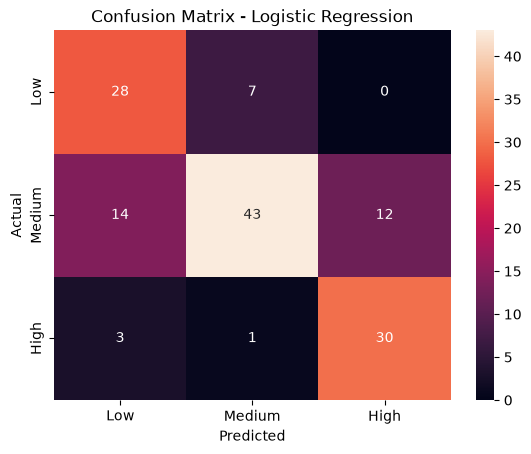

In [76]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["Low", "Medium", "High"]
)

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [77]:
print(df["Price_Tier"].value_counts())
print(df["Price_Tier"].value_counts(normalize=True) * 100)

Price_Tier
Medium    345
Low       173
High      171
Name: count, dtype: int64
Price_Tier
Medium    50.072569
Low       25.108853
High      24.818578
Name: proportion, dtype: float64


## 7.2. Decision Tree Classifier

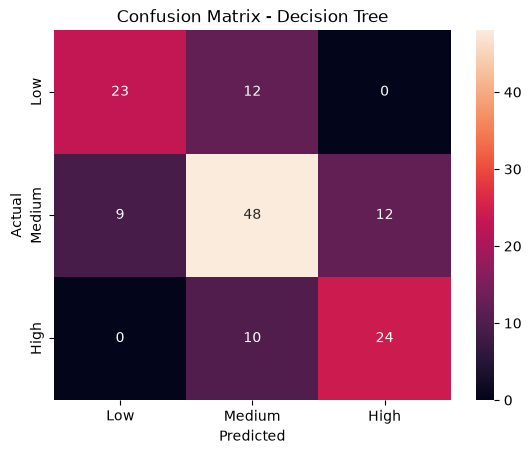

In [78]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=["Low", "Medium", "High"]
)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

# 8. So sánh 2 mô hình:

In [79]:
print("=== KẾT QUẢ SO SÁNH ===")

print("\nLogistic Regression:")
print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-score:  {logistic_f1:.4f}")

print("\nDecision Tree:")
print(f"Accuracy:  {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall:    {tree_recall:.4f}")
print(f"F1-score:  {tree_f1:.4f}")

print("\n=== NHẬN XÉT ===")
print("Logistic Regression có kết quả cao hơn Decision Tree trên cả 4 chỉ số Accuracy, Precision, Recall và F1-score.")
print("Do đó, Logistic Regression cho hiệu quả phân loại tốt hơn trong bài toán này.")

=== KẾT QUẢ SO SÁNH ===

Logistic Regression:
Accuracy:  0.7319
Precision: 0.7554
Recall:    0.7319
F1-score:  0.7304

Decision Tree:
Accuracy:  0.6884
Precision: 0.6894
Recall:    0.6884
F1-score:  0.6884

=== NHẬN XÉT ===
Logistic Regression có kết quả cao hơn Decision Tree trên cả 4 chỉ số Accuracy, Precision, Recall và F1-score.
Do đó, Logistic Regression cho hiệu quả phân loại tốt hơn trong bài toán này.


# 9. Chọn mô hình phù hợp:

In [80]:
if (
    logistic_accuracy > tree_accuracy
    and logistic_precision > tree_precision
    and logistic_recall > tree_recall
    and logistic_f1 > tree_f1
):
    best_model = model
    best_model_name = "Logistic Regression"
else:
    best_model = tree
    best_model_name = "Decision Tree"

print("Model được lựa chọn:", best_model_name)

Model được lựa chọn: Logistic Regression


In [81]:
result = X_test.copy()

result["Actual"] = y_test.values
result["Logistic_Predicted"] = y_pred_logistic
result["DecisionTree_Predicted"] = y_pred_tree

print(result[["Actual", "Logistic_Predicted", "DecisionTree_Predicted"]].head(20))

result.to_csv("classification_predictions.csv", index=False)

print("\nĐã xuất classification_predictions.csv")

     Actual Logistic_Predicted DecisionTree_Predicted
301    High               High                 Medium
497     Low                Low                 Medium
613     Low                Low                    Low
555  Medium             Medium                 Medium
377  Medium               High                 Medium
292  Medium                Low                   High
263  Medium                Low                 Medium
472  Medium               High                   High
265  Medium             Medium                 Medium
282  Medium             Medium                 Medium
57     High               High                   High
351  Medium             Medium                 Medium
149  Medium             Medium                 Medium
669     Low             Medium                 Medium
261  Medium             Medium                 Medium
93     High                Low                 Medium
255  Medium             Medium                 Medium
671  Medium             Medi

# 11. Lưu các file để bàn giao cho Tài – UI

In [82]:
import joblib

joblib.dump(best_model, "classification_model.pkl")
joblib.dump(scaler, "classification_scaler.pkl")
print("Đã xuất classification_model.pkl")
print("Đã xuất classification_scaler.pkl")

Đã xuất classification_model.pkl
Đã xuất classification_scaler.pkl
